## Testing the Price Impact Simulator

1. Building/Testing a L2Book that can simulate fills for orders and price impact using L2 MBP-10 Databento orderbook.
    1. The book should be able to simulate changes to the orderbook from orders. It should simulate market orders and IOC orders. It should also have a replenishment parameter.
    2. Order's have a latency parameter
2. Explore the predictive power of OBI via markouts. (to suport it's use in an execution strategy).
3. Milestone: Simulate one-step ahead order fill simulation with latencies, price protection (IOC ordertype) and replenishment(?)
4. Final: Simulate >1 step ahead, compare chunking a parent order via zero-intelligence constant fills vs OBI-aware strategies.
    1. Compare the summed arrival cost these two strategies with the mechanical price impact of sweeping the book with a single large order. (Should be arrival cost: immediate sweep > constant fills > obi adaptive or other strategy)
    2. See how dependent the strategies are on latency, replenishment, and asset (3 stocks from lecture 8, large/small tick, large/small cap)
    3. Possibly implement limit orders?

### Part 1: Dev/Testing Simulator


In [1]:
from dotenv import load_dotenv
import sys
sys.path.insert(0, '..')
import os
import databento as db
import numpy as np
import pandas as pd
import polars as pl
from saf_lib.helpers import DataBentoMBP10Adapter
from saf_lib.simulation import *
load_dotenv()

adapter = DataBentoMBP10Adapter(api_key=os.environ["DATABENTO_API_KEY"])
raw_data = adapter.get_data(
    tickers=["BKNG", "AMZN", "DRH"],
    start_date="2026-03-25",
    end_date="2026-03-27",
    dataset="XNAS.ITCH",
    cache_only=False
)
print(f"Loaded {len(raw_data):,} ticks")
print(f"Date range: {raw_data.index.min()} to {raw_data.index.max()}")
print(f"Columns: {raw_data.columns.tolist()}")

MBP10 AMZN,BKNG,DRH: 100%|██████████| 4/4 [00:00<00:00, 8180.02step/s, parquet cache hit] 


Loaded 5,879,570 ticks
Date range: 2026-03-25 09:30:00.000285597-04:00 to 2026-03-26 15:59:59.999797966-04:00
Columns: ['ts_event', 'rtype', 'publisher_id', 'instrument_id', 'action', 'side', 'depth', 'price', 'size', 'flags', 'ts_in_delta', 'sequence', 'bid_px_00', 'ask_px_00', 'bid_sz_00', 'ask_sz_00', 'bid_ct_00', 'ask_ct_00', 'bid_px_01', 'ask_px_01', 'bid_sz_01', 'ask_sz_01', 'bid_ct_01', 'ask_ct_01', 'bid_px_02', 'ask_px_02', 'bid_sz_02', 'ask_sz_02', 'bid_ct_02', 'ask_ct_02', 'bid_px_03', 'ask_px_03', 'bid_sz_03', 'ask_sz_03', 'bid_ct_03', 'ask_ct_03', 'bid_px_04', 'ask_px_04', 'bid_sz_04', 'ask_sz_04', 'bid_ct_04', 'ask_ct_04', 'bid_px_05', 'ask_px_05', 'bid_sz_05', 'ask_sz_05', 'bid_ct_05', 'ask_ct_05', 'bid_px_06', 'ask_px_06', 'bid_sz_06', 'ask_sz_06', 'bid_ct_06', 'ask_ct_06', 'bid_px_07', 'ask_px_07', 'bid_sz_07', 'ask_sz_07', 'bid_ct_07', 'ask_ct_07', 'bid_px_08', 'ask_px_08', 'bid_sz_08', 'ask_sz_08', 'bid_ct_08', 'ask_ct_08', 'bid_px_09', 'ask_px_09', 'bid_sz_09', 'ask_

In [2]:
symbol_map = {853 : "AMZN", 4576:"DRH", 2021:"BKNG"}
df = pl.from_pandas(raw_data)
# Returns an Int64 column of nanoseconds
df = df.with_columns(
    pl.col("ts_event").dt.timestamp("ns").alias("ts_event_nano")
)

cols = ["ts_event_nano", "instrument_id"] + [
    col for n in range(0, 10)
    for col in [f"bid_px_{str(n).zfill(2)}", f"ask_px_{str(n).zfill(2)}", f"bid_sz_{str(n).zfill(2)}", f"ask_sz_{str(n).zfill(2)}"]
]

df = df.select(cols)
df = df.unique(subset="ts_event_nano", keep="last").sort("ts_event_nano")
df

ts_event_nano,instrument_id,bid_px_00,ask_px_00,bid_sz_00,ask_sz_00,bid_px_01,ask_px_01,bid_sz_01,ask_sz_01,bid_px_02,ask_px_02,bid_sz_02,ask_sz_02,bid_px_03,ask_px_03,bid_sz_03,ask_sz_03,bid_px_04,ask_px_04,bid_sz_04,ask_sz_04,bid_px_05,ask_px_05,bid_sz_05,ask_sz_05,bid_px_06,ask_px_06,bid_sz_06,ask_sz_06,bid_px_07,ask_px_07,bid_sz_07,ask_sz_07,bid_px_08,ask_px_08,bid_sz_08,ask_sz_08,bid_px_09,ask_px_09,bid_sz_09,ask_sz_09
i64,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32,f64,f64,u32,u32
1774445400000121575,853,211.62,211.71,270,1,211.6,211.78,1,1,211.54,211.84,23,100,211.5,211.9,5,4,211.43,212.0,100,489,211.3,212.02,200,5,211.25,212.16,50,5,211.24,212.18,100,1,211.22,212.2,100,200,211.2,212.25,215,48
1774445400001006683,853,211.62,211.71,370,1,211.6,211.78,1,1,211.54,211.84,23,100,211.5,211.9,5,4,211.43,212.0,100,489,211.3,212.02,200,5,211.25,212.16,50,5,211.24,212.18,100,1,211.22,212.2,100,200,211.2,212.25,215,48
1774445400001156040,853,211.62,211.71,370,1,211.6,211.78,1,1,211.54,211.84,23,100,211.5,211.9,5,4,211.43,212.0,100,489,211.3,212.02,200,5,211.25,212.16,50,5,211.24,212.18,100,1,211.22,212.2,100,200,211.2,212.25,215,48
1774445400003182562,853,211.6,211.71,1,1,211.54,211.78,23,1,211.5,211.84,5,100,211.43,211.9,100,4,211.3,212.0,200,489,211.25,212.02,50,5,211.24,212.16,100,5,211.22,212.18,100,1,211.2,212.2,215,200,211.18,212.25,100,48
1774445400003232384,853,211.6,211.7,1,46,211.54,211.71,23,1,211.5,211.78,5,1,211.43,211.84,100,100,211.3,211.9,200,4,211.25,212.0,50,489,211.24,212.02,100,5,211.22,212.16,100,5,211.2,212.18,215,1,211.18,212.2,100,200
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
1774555199997348310,4576,9.58,9.59,3476,26416,9.57,9.6,10955,22902,9.56,9.61,5562,26202,9.55,9.62,12900,1600,9.54,9.63,3500,1200,9.53,9.64,2600,13100,9.51,9.65,13200,11900,9.48,9.72,11700,3800,9.47,9.73,11700,100,9.46,9.75,200,100
1774555199998183024,853,207.53,207.55,9660,171,207.52,207.56,16967,1,207.5,207.58,3229,447,207.49,207.59,2767,348,207.48,207.6,63,376,207.47,207.61,4000,100,207.46,207.62,4590,70,207.45,207.63,3801,5354,207.44,207.64,5733,300,207.43,207.65,3600,1873
1774555199998663846,4576,9.58,9.59,3476,26516,9.57,9.6,10955,22902,9.56,9.61,5562,26202,9.55,9.62,12900,1600,9.54,9.63,3500,1200,9.53,9.64,2600,13100,9.51,9.65,13200,11900,9.48,9.72,11700,3800,9.47,9.73,11700,100,9.46,9.75,200,100


### zero-intelligence executors

In [3]:
def _generate_letency(mu: int = 5_000_000, sigma: int = 2_000_000) -> int:
    """
    Generate a nanosecond latency
    
    Parameters
        ----------
        mu : int
            Mean (ns)
        sigma : int
            St deviation (ns)

        Returns
        -------
        int
            latency integer in nanoseconds
    """
    from scipy.stats import truncnorm
    # Parameters
    lower, upper = 0, float('inf')
    a, b = (lower - mu) / sigma, (upper - mu) / sigma
    rv = truncnorm(a, b, loc=mu, scale=sigma)
    latency_ns = int(rv.rvs(1)[0])
    return latency_ns

def naive_filler(side, parent_size, ts_nano, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    result = sim.accept_mkt_order(side, parent_size, ts_nano, latency_ns)
    df_new = sim.get_book_df()
    return result, df_new

def constant_filler(side: str, parent_size: int, start_ts_ns: int, wait_ns: int, 
                 n_chunks:int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    chunk_size = int(parent_size / n_chunks)
    times = np.arange(start_ts_ns, start_ts_ns + n_chunks * wait_ns, wait_ns)
    results = []
    for t in times:
        r = sim.accept_mkt_order(side, chunk_size, t, latency_ns)
        results.append(r)
    df_new = sim.get_book_df()
    return results, df_new

def constant_ioc_filler(side: str, limit_px: float, parent_size: int, start_ts_ns: int, wait_ns: int,
                 n_chunks:int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    chunk_size = int(parent_size / n_chunks)
    times = np.arange(start_ts_ns, start_ts_ns + n_chunks * wait_ns, wait_ns)
    results = []
    for t in times:
        r = sim.accept_ioc_lmt_order(side, limit_px, chunk_size, t, latency_ns)
        results.append(r)
    df_new = sim.get_book_df()
    return results, df_new

{'vwap': 209.42116, 'fills': [(209.43, 140), (209.42, 278), (209.41, 82)], 'total_filled': 500, 'levels_swept': 2, 'executed_at_ns': 1774533110179294494, 'executed_at_idx': 3131923, 'arrival_cost': 0.02884000000000242}


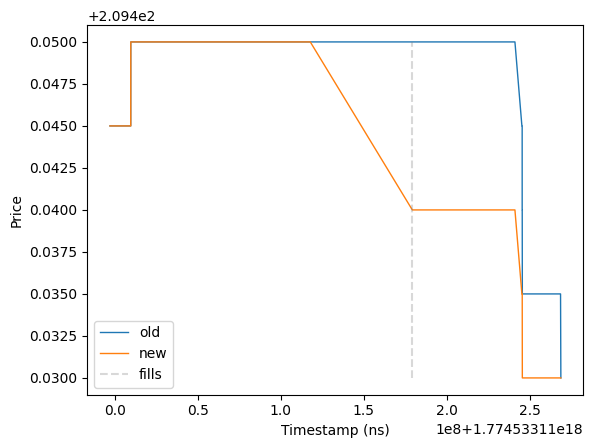

In [4]:
import matplotlib.pyplot as plt
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
PARENT_QTY = 500
SIDE="SELL"

results, new_df = naive_filler(SIDE, PARENT_QTY, TS_NANO, sim)

new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results['executed_at_idx']-20
i_end = results['executed_at_idx']+20
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
plt.vlines(results["executed_at_ns"], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
           linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()

[{'vwap': 210.98589, 'fills': [(211.0, 188), (210.99, 244), (210.98, 537), (210.97, 31)], 'total_filled': 1000, 'levels_swept': 3, 'executed_at_ns': 1774452497164870727, 'executed_at_idx': 1258902, 'arrival_cost': 0.029109999999974434}, {'vwap': 211.15756, 'fills': [(211.18, 20), (211.17, 228), (211.16, 344), (211.15, 304), (211.14, 104)], 'total_filled': 1000, 'levels_swept': 4, 'executed_at_ns': 1774452597150955842, 'executed_at_idx': 1273010, 'arrival_cost': 0.027440000000012787}, {'vwap': 211.12230000000002, 'fills': [(211.14, 188), (211.13, 294), (211.12, 150), (211.11, 296), (211.1, 72)], 'total_filled': 1000, 'levels_swept': 4, 'executed_at_ns': 1774452697122238037, 'executed_at_idx': 1289475, 'arrival_cost': 0.022699999999957754}, {'vwap': 211.09131, 'fills': [(211.12, 4), (211.1, 279), (211.09, 557), (211.08, 160)], 'total_filled': 1000, 'levels_swept': 3, 'executed_at_ns': 1774452797168156788, 'executed_at_idx': 1301236, 'arrival_cost': 0.04368999999999801}, {'vwap': 211.2174

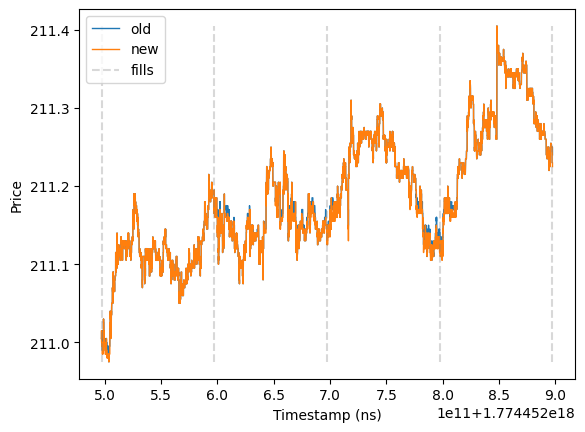

In [5]:
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
PARENT_QTY = 5000
SIDE="SELL"
WAIT_NS = 10 * 10e9 # 10s

results, new_df = constant_filler(SIDE, PARENT_QTY, TS_NANO, wait_ns=WAIT_NS, n_chunks=5, sim=sim)
new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results[0]['executed_at_idx']-10
i_end = results[-1]['executed_at_idx']+10
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
plt.vlines([r["executed_at_ns"] for r in results], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
           linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()

[{'vwap': 210.79985555555555, 'fills': [(210.82, 5), (210.81, 295), (210.8, 282), (210.79, 318)], 'total_filled': 900, 'levels_swept': 4, 'executed_at_ns': 1774453578707265834, 'executed_at_idx': 1394720, 'arrival_cost': 0.025144444444435976}, {'vwap': 211.01770000000002, 'fills': [(211.04, 139), (211.03, 138), (211.02, 281), (211.01, 238), (211.0, 204)], 'total_filled': 1000, 'levels_swept': 4, 'executed_at_ns': 1774453678621212418, 'executed_at_idx': 1405286, 'arrival_cost': 0.037299999999987676}, {'vwap': 210.96488, 'fills': [(210.99, 176), (210.98, 146), (210.97, 139), (210.96, 182), (210.95, 243), (210.94, 114)], 'total_filled': 1000, 'levels_swept': 5, 'executed_at_ns': 1774453778665211311, 'executed_at_idx': 1416855, 'arrival_cost': 0.04012000000000171}, {'vwap': 210.92204, 'fills': [(210.94, 124), (210.93, 244), (210.92, 344), (210.91, 288)], 'total_filled': 1000, 'levels_swept': 3, 'executed_at_ns': 1774453878617698138, 'executed_at_idx': 1427545, 'arrival_cost': 0.04295999999

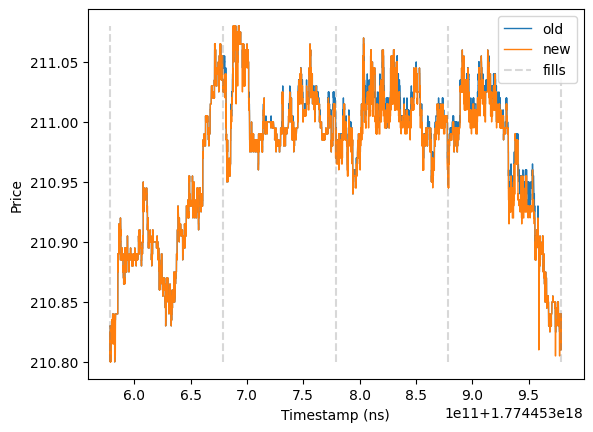

Total Filled: 4081 of 5000


In [6]:
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
LIMIT_PX = old_df.filter(pl.col("ts_event_nano") == TS_NANO)["bid_px_03"][0]
PARENT_QTY = 5000
SIDE="SELL"
WAIT_NS = 10 * 10e9 # 10s

results, new_df = constant_ioc_filler(SIDE, LIMIT_PX, PARENT_QTY, TS_NANO, wait_ns=WAIT_NS, n_chunks=5, sim=sim)

new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results[0]['executed_at_idx']-10
i_end = results[-1]['executed_at_idx']+10
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
plt.vlines([r["executed_at_ns"] for r in results], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
           linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()


print(f"Total Filled: {sum(r["total_filled"] for r in results)} of {PARENT_QTY}")

### Now the intelligent executors

In [ ]:
def obi_adaptive_filler(df: pl.DataFrame, side: str, limit_px: float, parent_size: int, max_size: int, threshold:float,
                        start_ts_ns: int, horizon: int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()
    df = df.with_row_index("idx")
    results = []
    remaining = parent_size
    start_idx = df.filter(pl.col("ts_event_nano") == start_ts_ns)["idx"][0]

    obi = ((df["bid_sz_00"] - df["ask_sz_00"]) / (df["bid_sz_00"] + df["ask_sz_00"]))[start_idx:]
    for row, idx in zip(df[start_idx:].iter_rows(named=True), range(len(df[start_idx:]))):
        ts_nano = row["ts_event_nano"]
        size = min(max_size * obi[idx], remaining)
        if obi[idx] > threshold and side == "BUY":
            r = sim.accept_ioc_lmt_order(side, limit_px, size, ts_nano, latency_ns)
            remaining -= r["total_filled"]
            results.append(r)
        if obi[idx] < threshold and side == "SELL":
            r = sim.accept_ioc_lmt_order(side, limit_px, size, ts_nano, latency_ns)
            remaining -= r["total_filled"]
            results.append(r)
        if remaining == 0:
            break
        if ts_nano > start_ts_ns + horizon:
            break

        #df = sim.get_book_df()
    
    return results, df

In [43]:
def obi_adaptive_filler(df: pl.DataFrame, side: str, limit_px: float, parent_size: int, max_size: int, threshold: float,
                        start_ts_ns: int, horizon: int, sim: ExecutionSimulator):
    latency_ns = _generate_letency()

    # Vectorized: slice to window, compute OBI + size, filter by threshold
    candidates = (
        df.filter(
            (pl.col("ts_event_nano") >= start_ts_ns) &
            (pl.col("ts_event_nano") <= start_ts_ns + horizon)
        )
        .with_columns(
            ((pl.col("bid_sz_00") - pl.col("ask_sz_00")) / (pl.col("bid_sz_00") + pl.col("ask_sz_00"))).alias("obi")
        )
        .with_columns(
            (pl.col("obi") * max_size).clip(0, None).cast(pl.Int64).alias("order_size")
        )
        .filter(
            pl.when(pl.lit(side == "BUY"))
            .then(pl.col("obi") > threshold)
            .otherwise(pl.col("obi") < threshold)
        )
    )

    # Sequential loop only over candidate rows (small fraction of original)
    results = []
    remaining = parent_size
    for row in candidates.iter_rows(named=True):
        size = min(row["order_size"], remaining)
        if size <= 0:
            continue
        r = sim.accept_ioc_lmt_order(side, limit_px, size, row["ts_event_nano"], latency_ns)
        remaining -= r["total_filled"]
        results.append(r)
        if remaining <= 0:
            break

    return results, sim.get_book_df()


In [44]:
# def obi_adaptive_filler(df: pl.DataFrame, side: str, limit_px: float, parent_size: int, max_size: int, threshold: float,
#                         start_ts_ns: int, horizon: int, sim: ExecutionSimulator):
#     latency_ns = _generate_letency()
#     results = []
#     remaining = parent_size
#     book_df = df
#     while remaining > 0:
#         # Vectorized: slice to window, recompute OBI from mutated book, filter
#         candidates = (
#             book_df.filter(
#                 (pl.col("ts_event_nano") >= start_ts_ns) &
#                 (pl.col("ts_event_nano") <= start_ts_ns + horizon)
#             )
#             .with_columns(
#                 ((pl.col("bid_sz_00") - pl.col("ask_sz_00")) / (pl.col("bid_sz_00") + pl.col("ask_sz_00"))).alias("obi")
#             )
#             .with_columns(
#                 (pl.col("obi") * max_size).clip(0, None).cast(pl.Int64).alias("order_size")
#             )
#             .filter(
#                 pl.when(pl.lit(side == "BUY"))
#                 .then(pl.col("obi") > threshold)
#                 .otherwise(pl.col("obi") < threshold)
#             )
#         )

#         if candidates.is_empty():
#             break

#         # Take the first candidate, fill it, then loop back to rebuild
#         row = candidates.row(0, named=True)
#         size = min(row["order_size"], remaining)
#         if size <= 0:
#             break
#         r = sim.accept_ioc_lmt_order(side, limit_px, size, row["ts_event_nano"], latency_ns)
#         remaining -= r["total_filled"]
#         results.append(r)

#         # Advance start so we don't re-visit this timestamp
#         start_ts_ns = row["ts_event_nano"] + 1

#         # Rebuild book df after each fill to reflect mutations
#         book_df = sim.get_book_df()


#     return results, sim.get_book_df()


[{'vwap': 212.41, 'fills': [(212.41, 18)], 'total_filled': 18, 'levels_swept': 0, 'executed_at_ns': 1774537714765088250, 'executed_at_idx': 3972415, 'arrival_cost': 0.01500000000001478}, {'vwap': 212.41, 'fills': [(212.41, 56)], 'total_filled': 56, 'levels_swept': 0, 'executed_at_ns': 1774537714878567986, 'executed_at_idx': 3972445, 'arrival_cost': 0.010000000000019327}, {'vwap': 212.41, 'fills': [(212.41, 6)], 'total_filled': 6, 'levels_swept': 0, 'executed_at_ns': 1774537714878567986, 'executed_at_idx': 3972445, 'arrival_cost': 0.010000000000019327}, {'vwap': 212.41, 'fills': [(212.41, 6)], 'total_filled': 6, 'levels_swept': 0, 'executed_at_ns': 1774537714891659423, 'executed_at_idx': 3972448, 'arrival_cost': 0.010000000000019327}, {'vwap': 212.41, 'fills': [(212.41, 6)], 'total_filled': 6, 'levels_swept': 0, 'executed_at_ns': 1774537714891659423, 'executed_at_idx': 3972448, 'arrival_cost': 0.010000000000019327}, {'vwap': 212.41, 'fills': [(212.41, 6)], 'total_filled': 6, 'levels_swe

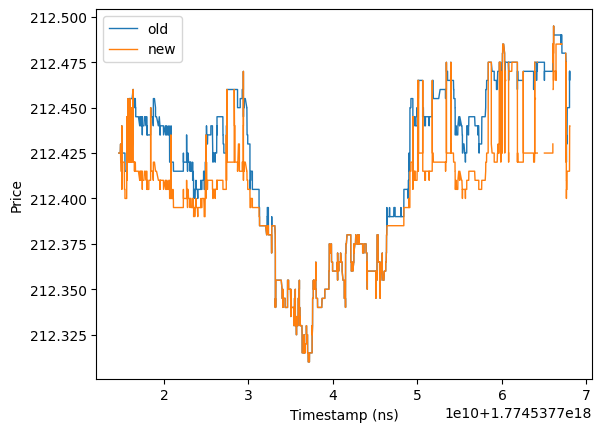

Total Filled: 5000 of 5000


In [45]:
old_df = df.filter(pl.col("instrument_id") == 853)
old_df = old_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
sim = ExecutionSimulator(old_df)
TS_NANO = old_df['ts_event_nano'].sample()[0]
LIMIT_PX = old_df.filter(pl.col("ts_event_nano") == TS_NANO)["bid_px_03"][0]
PARENT_QTY = 5000
SIDE="SELL"
MAX_SIZE = 100
OBI_THRESHOLD = 0.7
HORIZON = 3 * 60 * 60 * 10e9 # 1hr in ns

results, new_df = obi_adaptive_filler(old_df, SIDE, LIMIT_PX, PARENT_QTY, MAX_SIZE, OBI_THRESHOLD, TS_NANO, HORIZON, sim=sim)

new_df = new_df.with_columns(((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2).alias("mid"))
print(results)

i_start = results[0]['executed_at_idx']-10
i_end = results[-1]['executed_at_idx']+10
plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["mid"][i_start:i_end], label="old", linewidth=1)
plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["mid"][i_start:i_end], label="new", linewidth=1)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:blue", label="old ask", alpha=0.7)
# plt.plot(old_df['ts_event_nano'][i_start:i_end], old_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:blue", label="old bid", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["ask_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, linestyle="--", color="tab:orange", label="new ask", alpha=0.7)
# plt.plot(new_df['ts_event_nano'][i_start:i_end], new_df["bid_px_00"][i_start:i_end], marker="o", markersize = 2, linewidth=1, color="tab:orange", label="new bid", alpha=0.7)
# plt.vlines([r["executed_at_ns"] for r in results], ymin=min(new_df['mid'][i_start:i_end]), ymax=max(new_df['mid'][i_start:i_end]), 
#            linestyle="--", alpha=0.3, color="tab:gray", label="fills")
plt.ylabel("Price")
plt.xlabel("Timestamp (ns)")
plt.legend()
plt.show()


print(f"Total Filled: {sum(r["total_filled"] for r in results)} of {PARENT_QTY}")